# Лабораторна робота № 2 — теоретична частина
## Елементарний перцептрон Розенблатта: навчання за α- та γ-системами підкріплень

**Основа:** методичні матеріали «Лекція 2. Нейронні мережі» (особливо приклад 2.1, таблиці 2.1–2.5 та розділ 2.2.2 про α- і γ-системи підкріплень).

**Мета цього ноутбука:** розглянути архітектуру S–A–R, реалізувати порогові нейрони та на прикладі двох літер **Н** і **П** продемонструвати навчання і порівняння α- та γ-систем підкріплень.

**Зміст:**
1. Теоретичні поняття, формули й позначення.
2. Відтворення прикладу 2.1 із літерами Н і П (матриці, пороги та сигнали нейронів).
3. Реалізація α- і γ-коригування вихідних ваг, навчання та порівняння результатів.

> Практичне **індивідуальне завдання** винесене в окремий ноутбук. Для виконання цього потрібні лише `numpy`, `pandas`, `matplotlib`, `IPython`; GPU та підключення до інтернету не потрібні. Запускайте клітинки послідовно (Run All).

## 1. Теоретичні відомості та позначення

**Елементарний перцептрон** у методичних матеріалах складається з трьох послідовних груп:

- **S-елементи** — рецептори, що приймають чорно-біле зображення: $s_j\in\{0,1\}$.
- **A-елементи** — асоціативний шар з **фіксованими** вагами $W_{SA}$ і пороговою функцією:
  $$z_i=\sum_{j=1}^{n_S} w^{SA}_{ij}s_j,\qquad a_i=\mathbb{1}[z_i\ge\theta_{A_i}].$$
- **R-елемент** — вихідний нейрон зі змінними вагами $w_i^{AR}$ і біполярним сигналом:
  $$u_R=\sum_{i=1}^{n_A}w_i^{AR}a_i,\qquad R=\begin{cases}+1,&u_R\ge\theta_R,\\-1,&u_R<\theta_R.\end{cases}$$

**Навчання з учителем:** для бажаної відповіді $y\in\{-1,+1\}$ оновлюємо ваги тільки тоді, коли $R\ne y$. Нехай $\varepsilon>0$ — величина кроку; тоді *підписане підкріплення* $\eta = \varepsilon y$.

**α-система** (стор. 9–10, приклад 2.1):
$$\Delta w_i = \eta a_i,\quad w_i^{new}=\operatorname{clip}(w_i+\Delta w_i,0,1).$$
Активні зв'язки отримують однакову корекцію; неактивні не змінюються. Застосуємо обмеження ваг $[0,1]$ так само, як в чисельному прикладі PDF.

**γ-система** (формула (2.2), стор. 10–11):
$$\Delta w_i=\eta\left(a_i-\frac{N_{act}}{N}\right),\qquad N_{act}=\sum_i a_i,\quad N=n_A.$$
Звідси $\sum_i\Delta w_i=0$ — **сума вихідних ваг зберігається**. Коли виникає обмеження $0\le w_i\le1$, потрібно перерозподілити надлишок між іншими вагами (стор. 11–12, 19–21). Нижче для цього використовується **проєкція на перетин інтервалу $[0,1]$ з гіперплощиною сталої суми**. Це чисельно стійка реалізація принципу консервативності; вона **не зобов'язана відтворювати кожне округлене число** таблиці 2.5.

> **Примітка:** елементарний перцептрон у цьому прикладі має один R-нейрон, тому розрізняє два класи.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.precision', 4)
SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams['font.family'] = 'DejaVu Sans'  # кирилиця
print('NumPy:', np.__version__, '| Готово до роботи')

NumPy: 2.1.3 | Готово до роботи


In [2]:
def bipolar_step(u, threshold):
    """R-нейрон: рівність порогу відноситься до класу +1 (з допуском округлення)."""
    return np.where(np.asarray(u) >= np.asarray(threshold) - 1e-12, 1, -1)


def associative_layer(S, W_sa, theta_a):
    """S: (samples, pixels); W_sa: (neurons, pixels); theta_a: (neurons,)."""
    S = np.atleast_2d(np.asarray(S, dtype=float))
    W_sa = np.asarray(W_sa, dtype=float)
    theta_a = np.asarray(theta_a, dtype=float)
    z = S @ W_sa.T
    return z, (z >= theta_a[None, :] - 1e-12).astype(int)


def preview_patterns(patterns, labels, title='Вхідні зображення'):
    fig, axes = plt.subplots(1, len(patterns), figsize=(2.6 * len(patterns), 3))
    axes = np.atleast_1d(axes)
    for ax, letter, mat in zip(axes, labels, patterns):
        ax.imshow(mat, cmap='Greys', vmin=0, vmax=1, interpolation='nearest')
        ax.set_title(f'Літера «{letter}»')
        ax.set_xticks([]); ax.set_yticks([])
        for k in np.arange(-.5, mat.shape[0], 1): ax.axhline(k, color='gray', lw=.5)
        for k in np.arange(-.5, mat.shape[1], 1): ax.axvline(k, color='gray', lw=.5)
    fig.suptitle(title)
    plt.tight_layout(); plt.show()

## 2. Відтворення прикладу 2.1: літери Н та П

**З методичних матеріалів:** 9 S-нейронів, 6 A-нейронів і один біполярний R-нейрон, матриця S→A із таблиці 2.1 та початкові ваги A→R із таблиці 2.2 (стор. 12–14). Пороги $\theta_A=3.5$, $\theta_R=1.7$, крок $\varepsilon=0.1$ (стор. 15–16). Бажані виходи: **Н → −1, П → +1**.

У коді нижче спочатку перевіряємо результати **без прихованого коригування вхідних даних**.

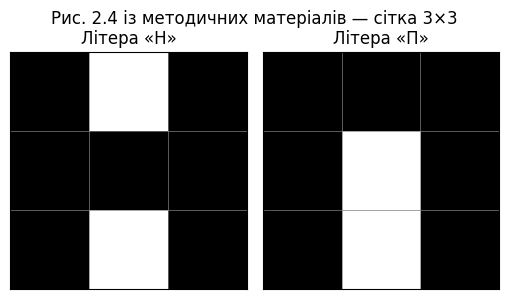

A1   A2   A3   A4   A5   A6
Джерело                Літера                              
Обчислено за табл. 2.1 Н       3.5  3.6  3.5  3.7  3.3  3.2
                       П       3.2  3.2  3.5  3.2  3.5  3.5
Наведено у табл. 2.3   Н       3.5  3.6  3.5  3.7  3.3  3.2
                       П       3.2  3.2  3.4  3.2  3.6  3.5

Розбіжності між розрахунком і табл. 2.3 (ненульові означають розбіжності):


,A1,A2,A3,A4,A5,A6
Н,0.0,0.0,0.0,0.0,0.0,0.0
П,0.0,-0.0,0.1,-0.0,-0.1,0.0


Фактично обчислені активації A: [[1, 1, 1, 1, 0, 0], [0, 0, 1, 0, 1, 1]]


In [3]:
# Дані табл. 2.1 (рядки A1...A6, стовпці S1...S9)
W_SA_REF = np.array([
    [.3,.2,.1,.6,.5,.4,.9,.6,.7],
    [.2,.1,.3,.4,.5,.6,.7,.1,.9],
    [.3,.5,.1,.6,.5,.4,.9,.4,.7],
    [.4,.3,.2,.1,.8,.7,.6,.6,.9],
    [.5,.3,.3,.6,.1,.2,.9,.2,.7],
    [.6,.5,.4,.1,.2,.3,.8,.5,.8],
], dtype=float)
W_R_REF = np.array([.2, .8, .6, .9, .8, .1])   # табл. 2.2
REF_LETTERS = ['Н', 'П']
S_REF = np.array([
    [[1,0,1],[1,1,1],[1,0,1]],  # Н: активні S1,S3,S4,S5,S6,S7,S9
    [[1,1,1],[1,0,1],[1,0,1]],  # П: активні S1,S2,S3,S4,S6,S7,S9
])
THETA_A_REF = np.full(6, 3.5)
THETA_R_REF = 1.7
Y_REF = np.array([-1, +1])
preview_patterns(S_REF, REF_LETTERS, 'Рис. 2.4 із методичних матеріалів — сітка 3×3')
Z_REF, A_REF_CALC = associative_layer(S_REF.reshape(2,9), W_SA_REF, THETA_A_REF)
TABLE_23 = np.array([[3.5,3.6,3.5,3.7,3.3,3.2],
                     [3.2,3.2,3.4,3.2,3.6,3.5]])
compare_ref = pd.concat({
    'Обчислено за табл. 2.1':pd.DataFrame(Z_REF, index=REF_LETTERS, columns=[f'A{i}' for i in range(1,7)]),
    'Наведено у табл. 2.3': pd.DataFrame(TABLE_23, index=REF_LETTERS, columns=[f'A{i}' for i in range(1,7)])
}, names=['Джерело','Літера'])
display(compare_ref)
print('Розбіжності між розрахунком і табл. 2.3 (ненульові означають розбіжності):')
display(pd.DataFrame(np.round(Z_REF-TABLE_23,4), index=REF_LETTERS,columns=[f'A{i}' for i in range(1,7)]))
assert np.allclose(Z_REF[0], TABLE_23[0]), 'Перевірка Н не пройдена'
print('Фактично обчислені активації A:', A_REF_CALC.tolist())

### 2.1. Увага до даних джерела: таблиця та пікселі можуть розходитися

При буквальному перемноженні матриці **табл. 2.1** і растрової **П** із рис. 2.4 значення для **A3** і **A5** виходять іншими, ніж у **табл. 2.3** (різниця $\pm 0.1$). Це суттєво: за порога 3.5 можуть активуватися інші A-елементи.

Для **демонстрації описаного у PDF алгоритму** нижче спеціально використаємо **табличні активації** A з табл. 2.3, а не приховано змінюватимемо ваги або зображення.

In [4]:
# Для відтворення прикладу з PDF беремо саме табличні A-активації.
A_REF = (TABLE_23 >= THETA_A_REF[None, :] - 1e-12).astype(int)
assert A_REF.tolist() == [[1,1,1,1,0,0],[0,0,0,0,1,1]]
U_REF = A_REF @ W_R_REF
R_REF = bipolar_step(U_REF, THETA_R_REF)
display(pd.DataFrame({'Літера':REF_LETTERS,
                      'Активні A':[' '.join(f'A{i+1}' for i in np.where(a)[0]) for a in A_REF],
                      'Вхід R': U_REF, 'До навчання': R_REF, 'Потрібно':Y_REF}))
assert np.allclose(U_REF, [2.5,0.9])
assert np.array_equal(R_REF, [1,-1])  # обидві відповіді спершу хибні

,Літера,Активні A,Вхід R,До навчання,Потрібно
0,Н,A1 A2 A3 A4,2.5,1,-1
1,П,A5 A6,0.9,-1,1


## 3. Реалізуємо α- і γ-системи

Для γ-корекції без досягнення меж: $w' = w + \varepsilon y(a-\bar a)$, де $\bar a=\frac{1}{N}\sum_i a_i$. У програмі застосована **обмежена проєкція**: знаходимо такий зсув $\lambda$, щоб

$$w'_i = \operatorname{clip}(w_i + \Delta w_i - \lambda,\,0,1),\qquad \sum_i w'_i=\sum_i w_i.$$

Бінарний пошук за $\lambda$ забезпечує одночасно **збереження суми** й обмеження **$0\le w_i\le1$** (з обчислювальною похибкою). Для α-корекції окремо обмежуємо ваги до $[0,1]$.

In [5]:
def project_box_fixed_sum(v, total, iterations=90):
    """Евклідова проєкція на {w: 0<=w<=1, sum(w)=total}."""
    v = np.asarray(v, dtype=float)
    if v.ndim != 1 or len(v) == 0 or not (0 <= total <= len(v)):
        raise ValueError('Недопустимі розміри або сумарна вага')
    if np.isclose(total, 0.0): return np.zeros_like(v)
    if np.isclose(total, float(len(v))): return np.ones_like(v)
    lo, hi = float(np.min(v) - 1.), float(np.max(v))
    for _ in range(iterations):
        mid = (lo + hi) / 2
        if np.clip(v - mid, 0, 1).sum() > total:
            lo = mid
        else:
            hi = mid
    return np.clip(v - (lo + hi)/2, 0, 1)


def update_weights(w, activation, wanted, predicted, lr=0.1, method='alpha'):
    """Один крок навчання ОДНОГО бінарного вихідного R-нейрона."""
    w = np.asarray(w, dtype=float).copy()
    a = np.asarray(activation, dtype=int)
    if len(w) != len(a): raise ValueError('Число ваг і A-нейронів має збігатися')
    if method not in ('alpha', 'gamma'): raise ValueError("method: 'alpha' або 'gamma'")
    if lr <= 0: raise ValueError('lr має бути додатним')
    if predicted == wanted: return w
    eta = lr * int(wanted)
    if method == 'alpha':
        return np.clip(w + eta*a, 0., 1.)
    proposal = w + eta*(a - a.mean())
    return project_box_fixed_sum(proposal, total=w.sum())


def predict_binary(A, w, threshold):
    return bipolar_step(np.asarray(A) @ np.asarray(w), threshold)


def train_binary(A, y, w_init, threshold, method='alpha', lr=.1,
                 max_epochs=60, sample_order=None):
    """Одна вага-векторна R-модель; лог після кожного пред'явлення."""
    A = np.asarray(A,dtype=int); y=np.asarray(y,dtype=int)
    w = np.asarray(w_init, dtype=float).copy()
    indices = range(len(y)) if sample_order is None else sample_order
    trace = [dict(step=0, epoch=0, sample='—', corrected=False, sum_w=w.sum(),
                  weights=w.copy(), n_errors=int(np.sum(predict_binary(A,w,threshold)!=y)))]
    step=0
    for epoch in range(1,max_epochs+1):
        for idx in indices:
            pred=int(predict_binary(A[idx],w,threshold))
            modified = pred != y[idx]
            w = update_weights(w, A[idx], y[idx], pred, lr, method)
            step+=1
            trace.append(dict(step=step,epoch=epoch,sample=int(idx),corrected=modified,
                              sum_w=w.sum(),weights=w.copy(),
                              n_errors=int(np.sum(predict_binary(A,w,threshold)!=y))))
        if np.array_equal(predict_binary(A,w,threshold),y):
            break
    return w, pd.DataFrame(trace), epoch

# Самоперевірка математичних властивостей.
tmp = project_box_fixed_sum(np.array([-3., .3, 2., .7]), total=1.8)
assert np.all((tmp>=-1e-10)&(tmp<=1+1e-10)) and abs(tmp.sum()-1.8)<1e-9
for a_test in ([1,0,1,0],[1,1,0,0],[1,0,0,0]):
    original=np.array([.2,.8,.6,.9]); y_test=-1
    adjusted=update_weights(original,a_test,y_test,predicted=1,method='gamma')
    assert abs(adjusted.sum()-original.sum()) < 1e-9
print('Тести для корекцій і збереження суми γ: OK')

Тести для корекцій і збереження суми γ: OK


### 3.1. Навчимо приклад Н/П обома способами

Використовуємо **однакові** початкові ваги, пороги, приклади та крок $0.1$. Після цього порівняємо кількість оновлень і суму ваг. Для відтворення табл. 2.4 наведемо окремо послідовність, коли після засвоєння **Н** пред'являють лише **П**.

,Метод,Епох,Кроків-пред’явлень,Оновлень,"Прогнози Н, П",Помилок наприкінці,Σ ваг (початок),Σ ваг (кінець)
0,α,6,12,9,"[-1, 1]",0,3.4,3.1
1,γ,5,10,9,"[-1, 1]",0,3.4,3.4


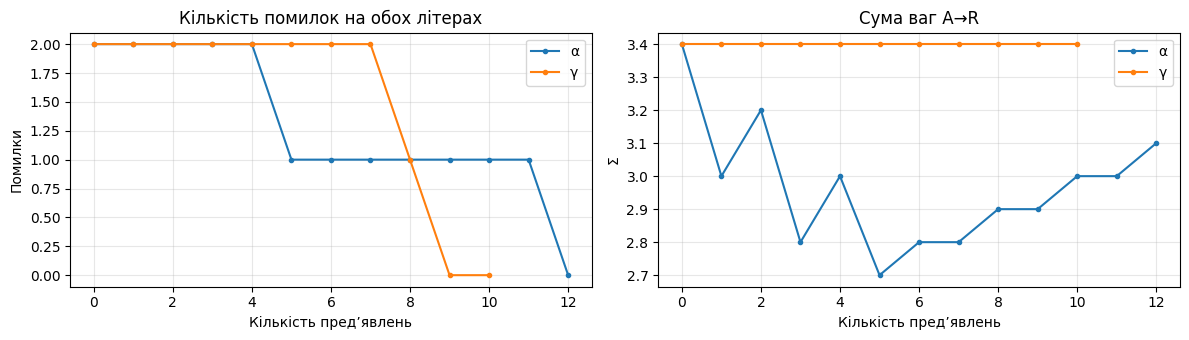

In [6]:
alpha_ref_w, alpha_ref_log, alpha_ref_epochs = train_binary(
    A_REF, Y_REF, W_R_REF, THETA_R_REF, 'alpha', .1)
gamma_ref_w, gamma_ref_log, gamma_ref_epochs = train_binary(
    A_REF, Y_REF, W_R_REF, THETA_R_REF, 'gamma', .1)

rows=[]
for name, final, log, epochs in [('α',alpha_ref_w,alpha_ref_log,alpha_ref_epochs),
                                 ('γ',gamma_ref_w,gamma_ref_log,gamma_ref_epochs)]:
    yhat=predict_binary(A_REF,final,THETA_R_REF)
    rows.append({'Метод':name,'Епох':epochs,
                 'Кроків-пред’явлень':len(log)-1,
                 'Оновлень':int(log.corrected.sum()),
                 'Прогнози Н, П':str(yhat.tolist()),
                 'Помилок наприкінці':int(sum(yhat!=Y_REF)),
                 'Σ ваг (початок)':W_R_REF.sum(),
                 'Σ ваг (кінець)':final.sum()})
display(pd.DataFrame(rows))
assert np.array_equal(predict_binary(A_REF,alpha_ref_w,THETA_R_REF),Y_REF)
assert np.array_equal(predict_binary(A_REF,gamma_ref_w,THETA_R_REF),Y_REF)
assert np.allclose(gamma_ref_log.sum_w.to_numpy(), W_R_REF.sum(),atol=1e-9)

fig, axs=plt.subplots(1,2,figsize=(12,3.5))
for log,label in [(alpha_ref_log,'α'),(gamma_ref_log,'γ')]:
    axs[0].plot(log.step,log.n_errors,marker='.',label=label)
    axs[1].plot(log.step,log.sum_w,marker='.',label=label)
axs[0].set_title('Кількість помилок на обох літерах')
axs[1].set_title('Сума ваг A→R')
for ax in axs: ax.set_xlabel('Кількість пред’явлень');ax.grid(alpha=.3);ax.legend()
axs[0].set_ylabel('Помилки');axs[1].set_ylabel('Σ')
plt.tight_layout();plt.show()

In [7]:
# Явне відтворення логіки табл. 2.4: Н, П, Н, П, Н, потім лише П
order_for_pdf = [0,1,0,1,0,1,1,1,1]
w=W_R_REF.copy()
reproduction=[]
for step, idx in enumerate(order_for_pdf, start=1):
    guess=int(predict_binary(A_REF[idx],w,THETA_R_REF))
    w=update_weights(w,A_REF[idx],Y_REF[idx],guess,method='alpha',lr=.1)
    reproduction.append({'t':f't{step}', 'Літера':REF_LETTERS[idx],
                         'Помилка': guess!=Y_REF[idx],
                         'U(Н)':round(float(A_REF[0]@w),4),
                         'U(П)':round(float(A_REF[1]@w),4),
                         **{f'w{i+1}':round(float(v),4) for i,v in enumerate(w)}})
display(pd.DataFrame(reproduction).set_index('t'))
assert np.array_equal(predict_binary(A_REF,w,THETA_R_REF),Y_REF)
print('Після t9 обидві літери розпізнаються; неактивні ваги при цьому зберігаються.')

,Літера,Помилка,U(Н),U(П),w1,w2,w3,w4,w5,w6
t,,,,,,,,,,
t1,Н,True,2.1,0.9,0.1,0.7,0.5,0.8,0.8,0.1
t2,П,True,2.1,1.1,0.1,0.7,0.5,0.8,0.9,0.2
t3,Н,True,1.7,1.1,0.0,0.6,0.4,0.7,0.9,0.2
t4,П,True,1.7,1.3,0.0,0.6,0.4,0.7,1.0,0.3
t5,Н,True,1.4,1.3,0.0,0.5,0.3,0.6,1.0,0.3
t6,П,True,1.4,1.4,0.0,0.5,0.3,0.6,1.0,0.4
t7,П,True,1.4,1.5,0.0,0.5,0.3,0.6,1.0,0.5
t8,П,True,1.4,1.6,0.0,0.5,0.3,0.6,1.0,0.6
t9,П,True,1.4,1.7,0.0,0.5,0.3,0.6,1.0,0.7


Після t9 обидві літери розпізнаються; неактивні ваги при цьому зберігаються.
